In [1]:
import sys
print(sys.executable)
print(sys.version)

/Library/Developer/CommandLineTools/usr/bin/python3
3.9.6 (default, Feb  3 2024, 15:58:27) 
[Clang 15.0.0 (clang-1500.3.9.4)]


In [3]:
%pip install --default-timeout=300 tensorflow scikit-learn pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 200.4 MB 67 kB/s  eta 0:00:011  |▎                               | 2.0 MB 2.6 MB/s eta 0:01:16     |█████                           | 30.9 MB 9.0 MB/s eta 0:00:19     |███████████████▌                | 97.2 MB 13.1 MB/s eta 0:00:08     |██████████████████▏             | 113.8 MB 3.5 MB/s eta 0:00:25     |██████████████████████████████▊ | 192.7 MB 32.2 MB/s eta 0:00:01
     |████████████████████████████████| 1.4 MB 1.4 MB/s eta 0:00:01
     |████████████████████████████████| 2.8 MB 4.2 MB/s eta 0:00:01
     |████████████████████████████████| 57 kB 12.3 MB/s eta 0:00:01
     |████████████████████████████████| 427 kB 6.5 MB/s eta 0:00:01
     |████████████████████████████████| 676 kB 4.9 MB/s eta 0:00:01
     |████████████████████████████████| 135 kB 5.6 MB/s eta 0:00:01
     |████████████████████████████████| 25.8 MB 10.7 MB/s eta 0:00:01
     |███████████████████████████

In [4]:
import tensorflow as tf

print(tf.__version__)
print("TensorFlow is ready!")

/Users/chaitanyapotnuru/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


2.20.0
TensorFlow is ready!


In [5]:
from tensorflow.keras.datasets import mnist

# Load the dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


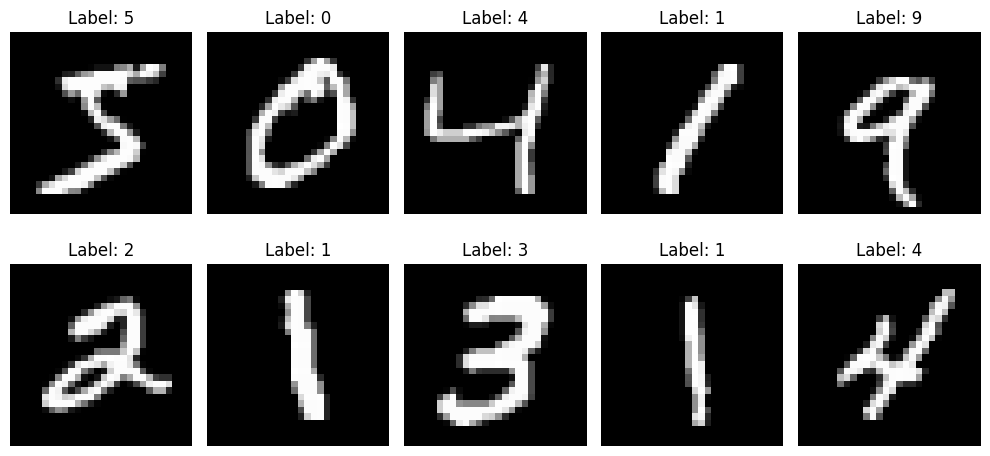

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import pandas as pd

# Check dataset dimensions
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# Check data types
print("Image data type:", x_train.dtype)
print("Label data type:", y_train.dtype)

# Check pixel value range
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

# Check unique digit labels
print("Unique labels:", np.unique(y_train))

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Image data type: uint8
Label data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]


0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


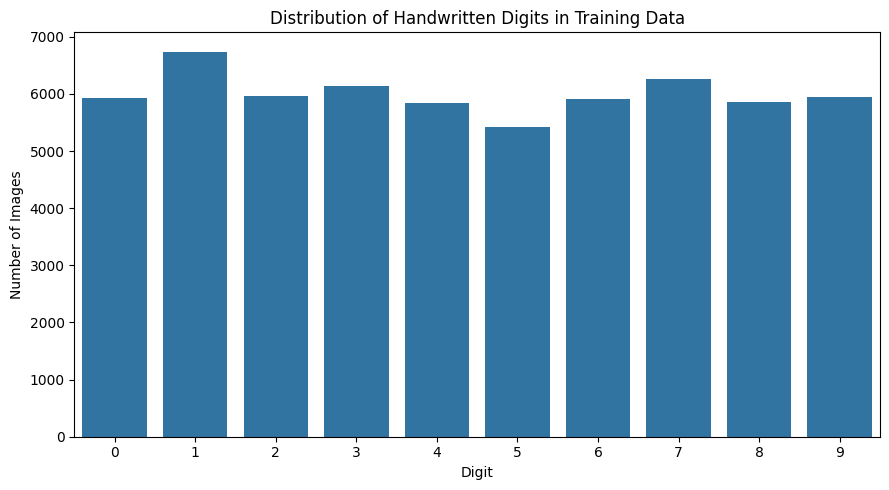

In [9]:

# Count images belonging to each digit
import seaborn as sns
digit_counts = pd.Series(y_train).value_counts().sort_index()

print(digit_counts)

# Plot the digit distribution
plt.figure(figsize=(9, 5))
sns.barplot(x=digit_counts.index, y=digit_counts.values)

plt.title("Distribution of Handwritten Digits in Training Data")
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.xticks(range(10))
plt.tight_layout()
plt.show()

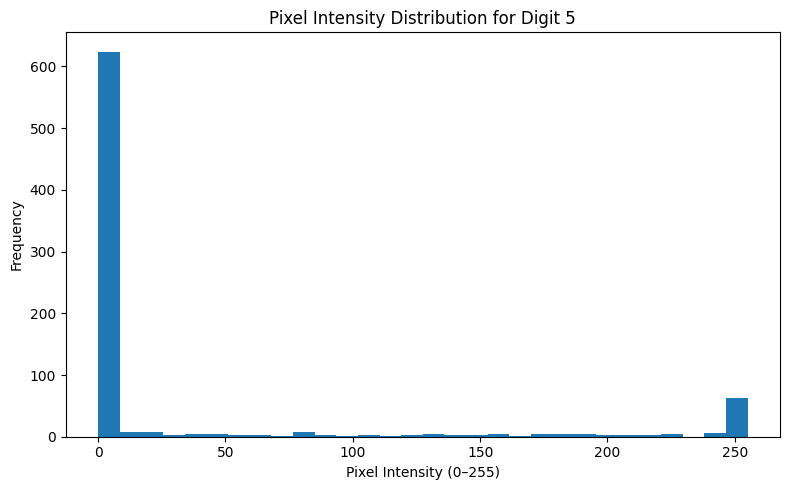

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(x_train[0].flatten(), bins=30)

plt.title(f"Pixel Intensity Distribution for Digit {y_train[0]}")
plt.xlabel("Pixel Intensity (0–255)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

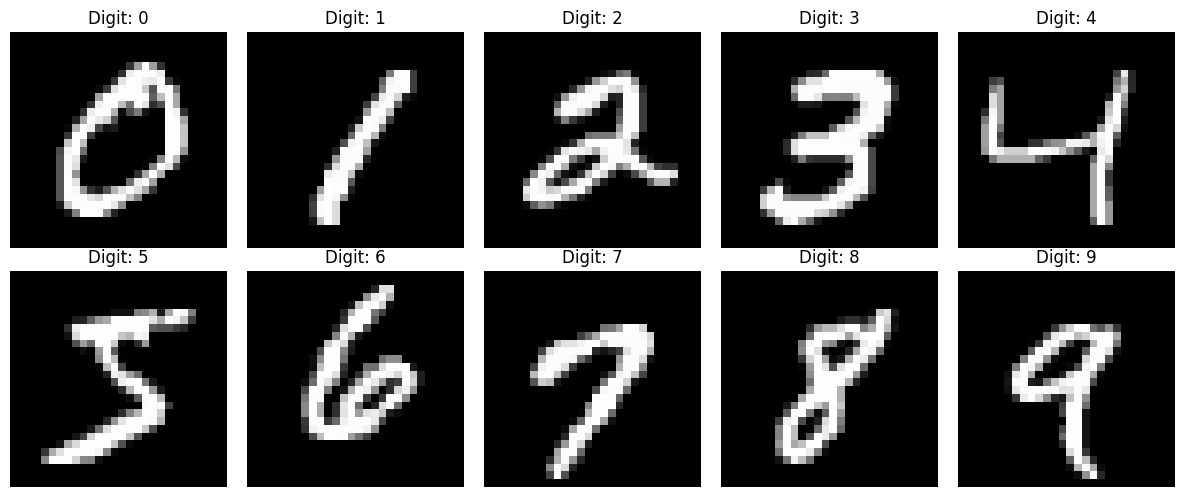

In [11]:
plt.figure(figsize=(12, 5))

for digit in range(10):
    index = np.where(y_train == digit)[0][0]

    plt.subplot(2, 5, digit + 1)
    plt.imshow(x_train[index], cmap="gray")
    plt.title(f"Digit: {digit}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Normalize pixel values
x_train_normalized = x_train.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

print("Training data:", x_train_normalized.shape)
print("Testing data:", x_test_normalized.shape)

print("Minimum pixel value:", x_train_normalized.min())
print("Maximum pixel value:", x_train_normalized.max())

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [13]:
# Flatten each image into 784 features
X_train_flat = x_train_normalized.reshape(x_train_normalized.shape[0], -1)
X_test_flat = x_test_normalized.reshape(x_test_normalized.shape[0], -1)

print("Flattened training data:", X_train_flat.shape)
print("Flattened testing data:", X_test_flat.shape)

Flattened training data: (60000, 784)
Flattened testing data: (10000, 784)


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

# Create the model
logistic_model = LogisticRegression(
    max_iter=100,
    solver="lbfgs"
)

# Train the model
start_time = time.time()

logistic_model.fit(X_train_flat, y_train)

training_time = time.time() - start_time

print("Training completed!")
print("Training time:", round(training_time, 2), "seconds")

Training completed!
Training time: 4.85 seconds


/Users/chaitanyapotnuru/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:
# Predict the test labels
y_pred_logistic = logistic_model.predict(X_test_flat)

# Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 92.56 %


In [16]:
from sklearn.neighbors import KNeighborsClassifier
import time

# Use a subset to speed up training
knn_sample_size = 20000

X_train_knn = X_train_flat[:knn_sample_size]
y_train_knn = y_train[:knn_sample_size]

knn_model = KNeighborsClassifier(
    n_neighbors=3,
    n_jobs=-1
)

start_time = time.time()

knn_model.fit(X_train_knn, y_train_knn)

knn_training_time = time.time() - start_time

print("KNN training completed!")
print("Training time:", round(knn_training_time, 2), "seconds")

KNN training completed!
Training time: 0.01 seconds


In [17]:
y_pred_knn = knn_model.predict(X_test_flat)

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 95.6 %


In [18]:
model_results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_accuracy * 100
    },
    {
        "Model": "KNN",
        "Accuracy": knn_accuracy * 100
    }
]

results_df = pd.DataFrame(model_results)
display(results_df.round(2))

,Model,Accuracy
0,Logistic Regression,92.56
1,KNN,95.60


In [19]:
from sklearn.svm import SVC
import time

svm_sample_size = 15000

X_train_svm = X_train_flat[:svm_sample_size]
y_train_svm = y_train[:svm_sample_size]

svm_model = SVC(kernel="rbf", C=5, gamma="scale")

start_time = time.time()

svm_model.fit(X_train_svm, y_train_svm)

svm_training_time = time.time() - start_time

print("SVM training completed!")
print("Training time:", round(svm_training_time, 2), "seconds")

SVM training completed!
Training time: 9.42 seconds


In [20]:
y_pred_svm = svm_model.predict(X_test_flat)

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

SVM Accuracy: 97.24 %


In [21]:
model_results.append({
    "Model": "SVM",
    "Accuracy": svm_accuracy * 100
})

results_df = pd.DataFrame(model_results)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

display(results_df.round(2))

,Model,Accuracy
0,SVM,97.24
1,KNN,95.60
2,Logistic Regression,92.56


In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

nn_model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

nn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = nn_model.fit(
    x_train_normalized,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7846 - loss: 0.7081 - val_accuracy: 0.9620 - val_loss: 0.1366
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 944us/step - accuracy: 0.9446 - loss: 0.1856 - val_accuracy: 0.9748 - val_loss: 0.0954
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 936us/step - accuracy: 0.9600 - loss: 0.1300 - val_accuracy: 0.9785 - val_loss: 0.0824
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step - accuracy: 0.9684 - loss: 0.1050 - val_accuracy: 0.9755 - val_loss: 0.0827
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - accuracy: 0.9732 - loss: 0.0879 - val_accuracy: 0.9790 - val_loss: 0.0689
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 996us/step - accuracy: 0.9750 - loss: 0.0781 - val_accuracy: 0.9787 - val_loss: 0.0707
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 927us/step - accuracy: 0.9793 - loss: 0.0636 - val_accuracy: 0.9782 - val_loss: 0.0726


In [24]:
nn_loss, nn_accuracy = nn_model.evaluate(
    x_test_normalized,
    y_test,
    verbose=0
)

print("Neural Network Accuracy:",
      round(nn_accuracy * 100, 2), "%")

Neural Network Accuracy: 97.68 %


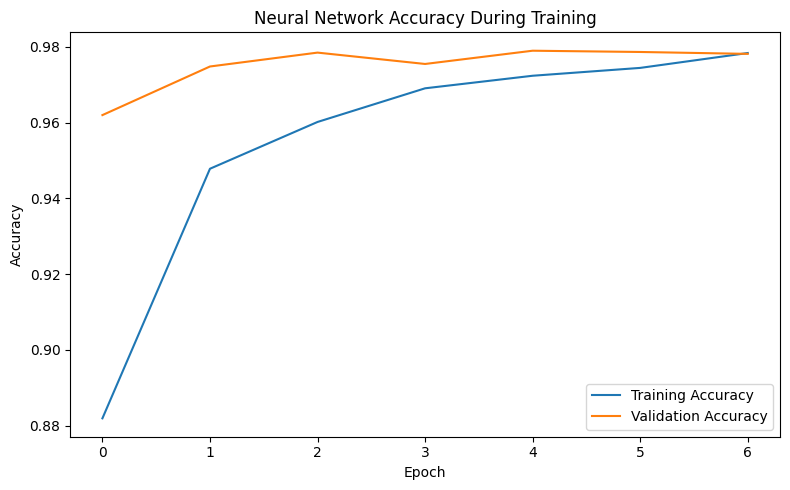

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Neural Network Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import classification_report

y_pred_nn = np.argmax(
    nn_model.predict(x_test_normalized, verbose=0),
    axis=1
)

print(classification_report(y_test, y_pred_nn))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.97      0.98      0.98      1010
           4       0.98      0.97      0.97       982
           5       0.98      0.97      0.98       892
           6       0.99      0.97      0.98       958
           7       0.97      0.98      0.97      1028
           8       0.97      0.97      0.97       974
           9       0.97      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



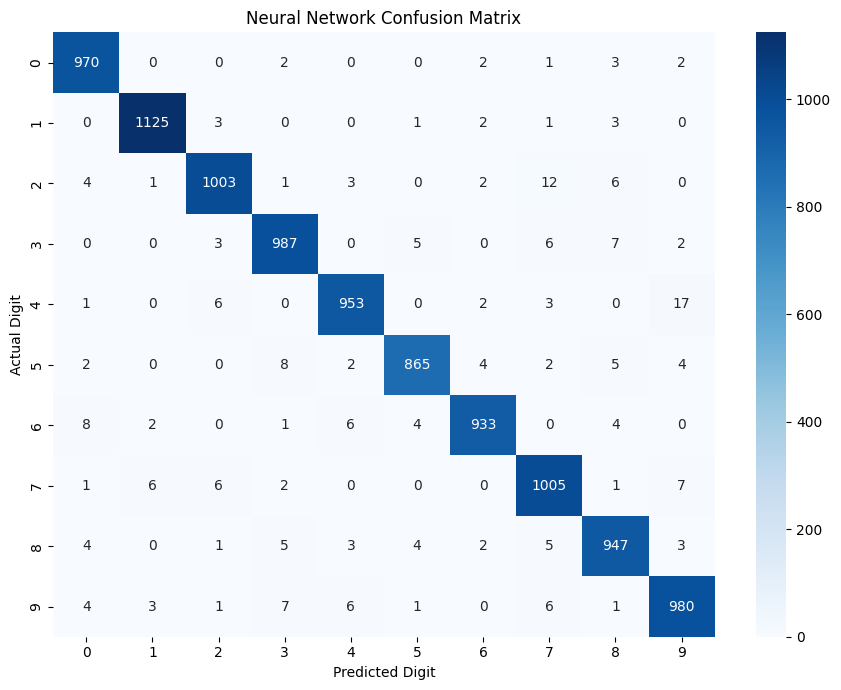

In [27]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_nn)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Neural Network Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.tight_layout()
plt.show()

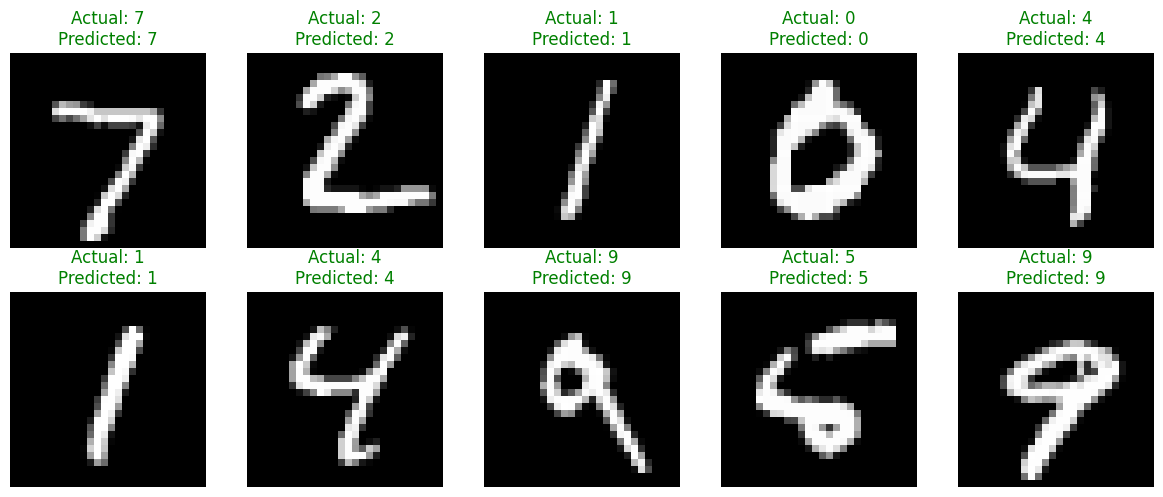

In [28]:
# Predict the first 10 test images
sample_images = x_test_normalized[:10]
sample_actual = y_test[:10]

sample_probabilities = nn_model.predict(sample_images, verbose=0)
sample_predictions = np.argmax(sample_probabilities, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")

    color = "green" if sample_predictions[i] == sample_actual[i] else "red"

    plt.title(
        f"Actual: {sample_actual[i]}\nPredicted: {sample_predictions[i]}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
nn_model.save("handwritten_digits_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [30]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Neural Network"
    ],
    "Accuracy (%)": [
        logistic_accuracy * 100,
        knn_accuracy * 100,
        svm_accuracy * 100,
        nn_accuracy * 100
    ]
})

final_comparison = final_comparison.sort_values(
    "Accuracy (%)", ascending=False
).reset_index(drop=True)

display(final_comparison.round(2))

,Model,Accuracy (%)
0,Neural Network,97.68
1,SVM,97.24
2,KNN,95.60
3,Logistic Regression,92.56


# Conclusion and Production Recommendation

The Handwritten Digits Recognition project uses the MNIST dataset to classify handwritten images into ten classes, representing digits from 0 to 9.

Exploratory data analysis was performed to inspect image dimensions, digit-label distribution, pixel intensity values, and sample images. Pixel values were normalized, and the images were flattened for traditional machine learning classifiers.

Four models were evaluated: Logistic Regression, K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and a Neural Network.

The observed test accuracies were:

- Logistic Regression: 92.56%
- KNN: 95.60%
- SVM: 97.24%
- Neural Network: 97.68%

The Neural Network achieved the highest observed accuracy and is the recommended candidate for further production evaluation. Before deployment, prediction latency, memory usage, robustness to different handwriting styles, and performance on representative real-world images should also be tested.

## Challenges Faced

1. **Image representation:** The images were stored as 28 × 28 pixel arrays. Flattening was used for traditional classifiers, while the neural network accepted the original image dimensions.
2. **Pixel scaling:** Pixel values originally ranged from 0 to 255. Normalization to 0–1 was used to make the input values more suitable for model training.
3. **Computational cost:** KNN and SVM can be computationally expensive on large datasets. Training subsets were used for these models to reduce computational requirements.
4. **Model comparison:** Different classifiers achieved different accuracy levels. Accuracy was used as the initial comparison metric, with classification reports and a confusion matrix used to examine the neural network's errors.
5. **Generalization:** High accuracy on MNIST does not guarantee equally strong performance on every real-world handwriting image. Additional testing is needed before production deployment.

## Future Enhancements

- Evaluate additional neural network architectures, including convolutional neural networks (CNNs).
- Compare inference speed and memory consumption across models.
- Test the system using handwritten images collected outside MNIST.
- Develop a simple interface where users can upload a digit image and receive a prediction.
